# 06 — Benchmark: neural versus classical identification

This notebook merges the classical sweep (notebook 02) with the neural sweep (notebook 03) on their common configurations, and exports the tables and figures used in the paper.

* **Equation recovery.** Relative coefficient error $\|\hat\Xi-\Xi\|_F/\|\Xi\|_F$ and support $F_1$. For N1 these are computed from the distilled equations.
* **Short-term forecasting.** Valid prediction time (VPT), in Lyapunov times, until the normalised error first exceeds 0.4. It is computed from 16 in-distribution and 16 out-of-distribution initial conditions.
* **Long-term statistics.** Mean 1-D Wasserstein distance between invariant marginals (in standard deviations), Benettin estimate of $\lambda_{\max}$, and the fraction of free runs that diverge.

In [1]:
import sys, os, json, pickle
sys.path.insert(0, os.path.abspath(".."))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from src import experiment as E, plotting as P
from src.library import PolyLibrary
from src.sindy import poly_field
from src.integrators import rollout_np
from src.node import rollout_model
P.setup()
MET = "../results/metrics"
cl = pd.read_csv(f"{MET}/classical_grid.csv"); nn = pd.read_csv(f"{MET}/neural_grid.csv")
cl = cl[(cl.irregular == False) & cl.system.isin(["lorenz", "lv4"])]
nn = nn[nn["error"].isna()] if "error" in nn else nn
df = pd.concat([cl, nn], ignore_index=True)
df["dt_ratio"] = df.dt_ratio.round(5)
CONFIGS = [(round(r, 5), 0.01) for r in E.DT_RATIOS] + [(round(1/15, 5), e) for e in [0.0, 0.02, 0.05, 0.10, 0.20]]
common = df[[ (r, e) in CONFIGS for r, e in zip(df.dt_ratio, df.noise)]].copy()
METHODS = ["C1-OLS", "C2-SINDy-FD", "C2-SINDy-SG", "C3-WSINDy", "N1-MLP", "N2-Lib", "N2-Lib-WS"]
common = common[common.method.isin(METHODS)]
lyap = {"lorenz": 0.9056, "lv4": 0.0203}
common["exact_support"] = common.exact_support.astype(str).str.lower().eq("true").astype(float)
common["lyap_relerr"] = np.abs(common.lyap_est - common.system.map(lyap)) / common.system.map(lyap)
print(common.groupby(["system", "method"]).size().unstack())

method  C1-OLS  C2-SINDy-FD  C2-SINDy-SG  C3-WSINDy  N1-MLP  N2-Lib  N2-Lib-WS
system                                                                        
lorenz      27           27           27         27      27      27         27
lv4         27           27           27         27      27      27         27


## Equation recovery across the cross-shaped grid

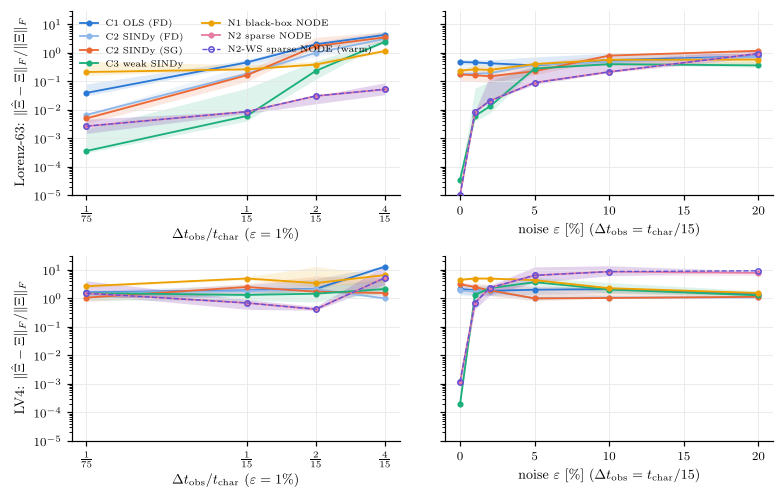

In [2]:
def med_iqr(g, col):
    return g[col].median(), g[col].quantile(0.25), g[col].quantile(0.75)

fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.6), sharey="row")
for i, name in enumerate(["lorenz", "lv4"]):
    for j, sweep in enumerate(["dt", "noise"]):
        ax = axes[i, j]
        for m in METHODS:
            sub = common[(common.system == name) & (common.method == m)]
            if sweep == "dt":
                sub = sub[sub.noise == 0.01]; xs = sorted(sub.dt_ratio.unique()); key = "dt_ratio"
            else:
                sub = sub[sub.dt_ratio == round(1/15, 5)]; xs = sorted(sub.noise.unique()); key = "noise"
            stats = np.array([med_iqr(sub[sub[key] == x], "coef_err") for x in xs])
            if not len(stats): continue
            xv = np.array(xs) * (100 if sweep == "noise" else 1)
            ws = m == "N2-Lib-WS"
            ax.plot(xv, stats[:, 0], "o--" if ws else "o-", ms=3.5 if ws else 3, color=P.COLORS[m], label=P.LABELS[m],
                    mfc="none" if ws else P.COLORS[m], lw=0.9 if ws else 1.2, zorder=3 if ws else 2)
            ax.fill_between(xv, stats[:, 1], stats[:, 2], color=P.COLORS[m], alpha=0.15, lw=0)
        ax.set_yscale("log"); ax.set_ylim(1e-5, 30)
        if sweep == "dt":
            ax.set_xscale("log"); ax.set_xticks([1/75, 1/15, 2/15, 4/15]); ax.set_xticklabels([r"$\frac{1}{75}$", r"$\frac{1}{15}$", r"$\frac{2}{15}$", r"$\frac{4}{15}$"])
            ax.minorticks_off(); ax.set_xlabel(r"$\Delta t_{\rm obs}/t_{\rm char}$ ($\varepsilon=1\%$)")
        else:
            ax.set_xlabel(r"noise $\varepsilon$ [\%] ($\Delta t_{\rm obs}=t_{\rm char}/15$)")
        if j == 0: ax.set_ylabel(("Lorenz-63" if name == "lorenz" else "LV4") + r": $\|\hat\Xi-\Xi\|_F/\|\Xi\|_F$")
axes[0, 0].legend(frameon=False, fontsize=6, ncol=2, loc="upper left")
fig.tight_layout()
P.save(fig, "fig06_benchmark_coef")
plt.show()

## Forecast skill: valid prediction time, in- and out-of-distribution

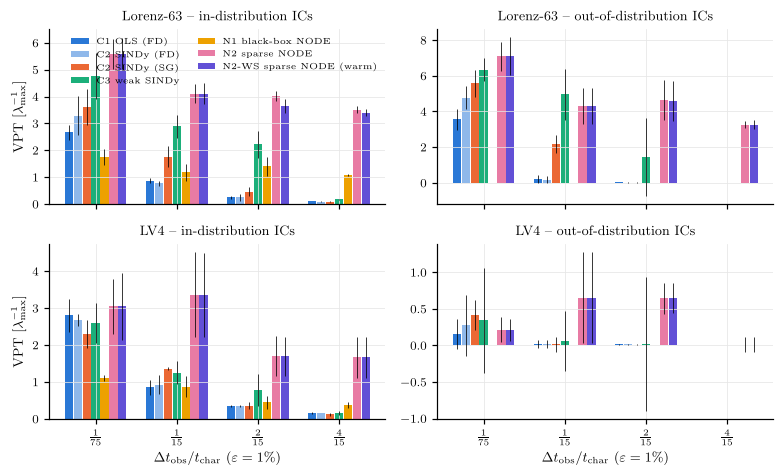

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.4), sharex=True)
w = 0.11
xs = [round(r, 5) for r in E.DT_RATIOS]
for i, name in enumerate(["lorenz", "lv4"]):
    for j, tag in enumerate(["id", "ood"]):
        ax = axes[i, j]
        for k, m in enumerate(METHODS):
            sub = common[(common.system == name) & (common.method == m) & (common.noise == 0.01)]
            v = [sub[sub.dt_ratio == x][f"vpt_{tag}"].median() for x in xs]
            e = [sub[sub.dt_ratio == x][f"vpt_{tag}"].std() for x in xs]
            ax.bar(np.arange(4) + (k - 3) * w, v, w * 0.92, yerr=e, color=P.COLORS[m], label=P.LABELS[m],
                   error_kw=dict(lw=0.5, capsize=0))
        ax.set_xticks(range(4)); ax.set_xticklabels([r"$\frac{1}{75}$", r"$\frac{1}{15}$", r"$\frac{2}{15}$", r"$\frac{4}{15}$"])
        ax.set_title(("Lorenz-63" if name == "lorenz" else "LV4") + (" -- in-distribution ICs" if tag == "id" else " -- out-of-distribution ICs"))
        if j == 0: ax.set_ylabel(r"VPT [$\lambda_{\max}^{-1}$]")
        if i == 1: ax.set_xlabel(r"$\Delta t_{\rm obs}/t_{\rm char}$ ($\varepsilon=1\%$)")
axes[0, 0].legend(frameon=False, fontsize=5.8, ncol=2)
fig.tight_layout()
P.save(fig, "fig06_vpt")
plt.show()

## Summary tables

In [4]:
cols = {"coef_err": "coef. err.", "f1": "$F_1$", "vpt_id": "VPT$_{\\rm ID}$", "vpt_ood": "VPT$_{\\rm OOD}$",
        "w1": "$W_1$", "lyap_relerr": "$|\\hat\\lambda-\\lambda|/\\lambda$", "diverged_long": "div."}
names = {"C1-OLS": "C1 OLS (FD)", "C2-SINDy-FD": "C2 SINDy (FD)", "C2-SINDy-SG": "C2 SINDy (SG)",
         "C3-WSINDy": "C3 weak SINDy", "N1-MLP": "N1 black-box NODE$^\\dagger$", "N2-Lib": "N2 sparse NODE",
         "N2-Lib-WS": "N2-WS (warm start)"}
tabs = {}
for name in ["lorenz", "lv4"]:
    blocks = []
    for (r, e, lab) in [(round(1/15, 5), 0.01, "moderate"), (round(4/15, 5), 0.01, "sparse"), (round(1/15, 5), 0.10, "noisy")]:
        sub = common[(common.system == name) & (common.dt_ratio == r) & (common.noise == e)]
        t = sub.groupby("method")[list(cols)].median().reindex(METHODS)
        t.columns = pd.MultiIndex.from_product([[lab], [cols[c] for c in cols]])
        blocks.append(t)
    tabs[name] = pd.concat(blocks, axis=1)
    tabs[name].to_csv(f"{MET}/table_{name}.csv")
tabs["lorenz"].round(3)

moderate                                               \
            coef. err.  $F_1$ VPT$_{\rm ID}$ VPT$_{\rm OOD}$  $W_1$   
method                                                                
C1-OLS           0.459  0.378          0.864           0.216  0.081   
C2-SINDy-FD      0.183  0.667          0.770           0.185  0.161   
C2-SINDy-SG      0.163  0.636          1.768           2.178  0.115   
C3-WSINDy        0.006  1.000          2.901           4.962  0.140   
N1-MLP           0.262  0.824          1.174           0.015  0.215   
N2-Lib           0.009  1.000          4.110           4.299  0.107   
N2-Lib-WS        0.009  1.000          4.110           4.301  0.173   

                                                     sparse         \
            $|\hat\lambda-\lambda|/\lambda$ div. coef. err.  $F_1$   
method                                                               
C1-OLS                                0.059  0.0      4.250  0.378   
C2-SINDy-FD                           0.037  0.0      3.095  0.378   
C2-SINDy-SG                           0.010  0.0      3.474  0.389   
C3-WSINDy                             0.024  0.0      2.430  0.462   
N1-MLP                                0.115  0.0      1.153  0.452   
N2-Lib                                0.014  0.0      0.052  0.636   
N2-Lib-WS                             0.014  0.0      0.052  0.636   

                            ...                                              \
            VPT$_{\rm ID}$  ...  $W_1$ $|\hat\lambda-\lambda|/\lambda$ div.   
method                      ...                                               
C1-OLS               0.112  ...    NaN                             NaN  1.0   
C2-SINDy-FD          0.086  ...  1.531                           1.000  1.0   
C2-SINDy-SG          0.088  ...  1.531                           1.000  1.0   
C3-WSINDy            0.174  ...  1.110                           1.555  0.0   
N1-MLP               1.080  ...  0.170                           0.063  0.0   
N2-Lib               3.512  ...  0.084                           0.026  0.0   
N2-Lib-WS            3.402  ...  0.084                           0.027  0.0   

                 noisy                                               \
            coef. err.  $F_1$ VPT$_{\rm ID}$ VPT$_{\rm OOD}$  $W_1$   
method                                                                
C1-OLS           0.553  0.378          0.594           0.131  0.051   
C2-SINDy-FD      0.477  0.800          0.674           0.155  0.077   
C2-SINDy-SG      0.797  0.483          0.681           0.139  0.110   
C3-WSINDy        0.400  0.483          1.662           0.061  0.144   
N1-MLP           0.569  0.519          1.379           0.016  0.296   
N2-Lib           0.213  0.560          1.884           0.545  0.119   
N2-Lib-WS        0.215  0.560          2.033           0.994  0.051   

                                                  
            $|\hat\lambda-\lambda|/\lambda$ div.  
method                                            
C1-OLS                                0.224  0.0  
C2-SINDy-FD                           0.128  0.0  
C2-SINDy-SG                           0.267  0.0  
C3-WSINDy                             0.022  0.0  
N1-MLP                                0.161  0.0  
N2-Lib                                0.030  0.0  
N2-Lib-WS                             0.024  0.0  

[7 rows x 21 columns]

In [5]:
tabs["lv4"].round(3)

moderate                                               \
            coef. err.  $F_1$ VPT$_{\rm ID}$ VPT$_{\rm OOD}$  $W_1$   
method                                                                
C1-OLS           1.910  0.442          0.859           0.020  0.073   
C2-SINDy-FD      1.801  0.429          0.918           0.021  0.159   
C2-SINDy-SG      2.509  0.432          1.362           0.014  0.242   
C3-WSINDy        1.323  0.484          1.255           0.060  0.084   
N1-MLP           4.978  0.453          0.875           0.011  0.225   
N2-Lib           0.692  0.447          3.357           0.651  0.029   
N2-Lib-WS        0.692  0.447          3.357           0.651  0.029   

                                                     sparse         \
            $|\hat\lambda-\lambda|/\lambda$ div. coef. err.  $F_1$   
method                                                               
C1-OLS                                0.265  0.0     13.003  0.442   
C2-SINDy-FD                           0.537  0.0      1.000  0.000   
C2-SINDy-SG                           0.958  0.0      1.543  0.000   
C3-WSINDy                             0.078  0.0      2.130  0.207   
N1-MLP                                0.966  0.0      6.560  0.447   
N2-Lib                                0.127  0.0      5.235  0.442   
N2-Lib-WS                             0.108  0.0      5.235  0.442   

                            ...                                               \
            VPT$_{\rm ID}$  ...   $W_1$ $|\hat\lambda-\lambda|/\lambda$ div.   
method                      ...                                                
C1-OLS               0.156  ...   0.282                           0.980  1.0   
C2-SINDy-FD          0.159  ...   0.798                           1.000  0.0   
C2-SINDy-SG          0.120  ...  35.938                           0.963  0.0   
C3-WSINDy            0.162  ...   0.798                           0.994  0.0   
N1-MLP               0.381  ...   0.499                           0.924  0.0   
N2-Lib               1.670  ...   0.118                           0.257  0.0   
N2-Lib-WS            1.670  ...   0.118                           0.257  0.0   

                 noisy                                               \
            coef. err.  $F_1$ VPT$_{\rm ID}$ VPT$_{\rm OOD}$  $W_1$   
method                                                                
C1-OLS           2.113  0.442          0.621           0.012  0.178   
C2-SINDy-FD      1.071  0.320          0.415           0.011  0.479   
C2-SINDy-SG      1.029  0.400          0.583           0.011  0.798   
C3-WSINDy        2.042  0.423          0.291           0.011  1.177   
N1-MLP           2.274  0.444          0.757           0.011  0.253   
N2-Lib           8.700  0.442          0.958           0.009  0.107   
N2-Lib-WS        8.700  0.442          0.958           0.009  0.107   

                                                  
            $|\hat\lambda-\lambda|/\lambda$ div.  
method                                            
C1-OLS                                0.456  0.0  
C2-SINDy-FD                           0.991  0.0  
C2-SINDy-SG                           1.000  1.0  
C3-WSINDy                             1.000  0.0  
N1-MLP                                0.948  0.0  
N2-Lib                                0.057  0.0  
N2-Lib-WS                             0.057  0.0  

[7 rows x 21 columns]

In [6]:
def fmt(v, c):
    if pd.isna(v): return "--"
    if c in ("coef. err.",):
        return f"{v:.1e}".replace("e-0", "e-").replace("e+0", "e") if v < 0.01 else f"{v:.2f}"
    return f"{v:.2f}"

def latex_table(t, keep=("coef. err.", "$F_1$", "VPT$_{\\rm ID}$", "VPT$_{\\rm OOD}$", "$W_1$")):
    regimes = list(dict.fromkeys(t.columns.get_level_values(0)))
    head = " & " + " & ".join([f"\\multicolumn{{{len(keep)}}}{{c}}{{{r}}}" for r in regimes]) + " \\\\\n"
    sub = " & " + " & ".join(list(keep) * len(regimes)) + " \\\\\n"
    body = ""
    for m in t.index:
        vals = []
        for r in regimes:
            for c in keep:
                vals.append(fmt(t.loc[m, (r, c)], c))
        body += names[m] + " & " + " & ".join(vals) + " \\\\\n"
    return head, sub, body

for name in ["lorenz", "lv4"]:
    head, sub, body = latex_table(tabs[name])
    with open(f"{MET}/table_{name}.tex", "w") as fh:
        fh.write(head + "\\midrule\n" + sub + "\\midrule\n" + body)
print(open(f"{MET}/table_lorenz.tex").read())

 & \multicolumn{5}{c}{moderate} & \multicolumn{5}{c}{sparse} & \multicolumn{5}{c}{noisy} \\
\midrule
 & coef. err. & $F_1$ & VPT$_{\rm ID}$ & VPT$_{\rm OOD}$ & $W_1$ & coef. err. & $F_1$ & VPT$_{\rm ID}$ & VPT$_{\rm OOD}$ & $W_1$ & coef. err. & $F_1$ & VPT$_{\rm ID}$ & VPT$_{\rm OOD}$ & $W_1$ \\
\midrule
C1 OLS (FD) & 0.46 & 0.38 & 0.86 & 0.22 & 0.08 & 4.25 & 0.38 & 0.11 & 0.01 & -- & 0.55 & 0.38 & 0.59 & 0.13 & 0.05 \\
C2 SINDy (FD) & 0.18 & 0.67 & 0.77 & 0.18 & 0.16 & 3.09 & 0.38 & 0.09 & 0.01 & 1.53 & 0.48 & 0.80 & 0.67 & 0.16 & 0.08 \\
C2 SINDy (SG) & 0.16 & 0.64 & 1.77 & 2.18 & 0.11 & 3.47 & 0.39 & 0.09 & 0.01 & 1.53 & 0.80 & 0.48 & 0.68 & 0.14 & 0.11 \\
C3 weak SINDy & 6.1e-3 & 1.00 & 2.90 & 4.96 & 0.14 & 2.43 & 0.46 & 0.17 & 0.01 & 1.11 & 0.40 & 0.48 & 1.66 & 0.06 & 0.14 \\
N1 black-box NODE$^\dagger$ & 0.26 & 0.82 & 1.17 & 0.02 & 0.22 & 1.15 & 0.45 & 1.08 & 0.02 & 0.17 & 0.57 & 0.52 & 1.38 & 0.02 & 0.30 \\
N2 sparse NODE & 8.6e-3 & 1.00 & 4.11 & 4.30 & 0.11 & 0.05 & 0.64 & 3.51

## Reconstructed attractors: free runs of every identified model

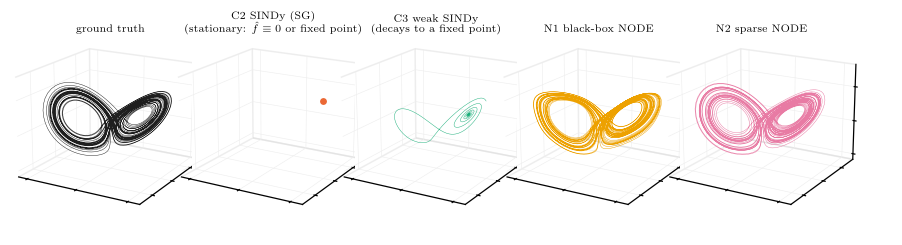

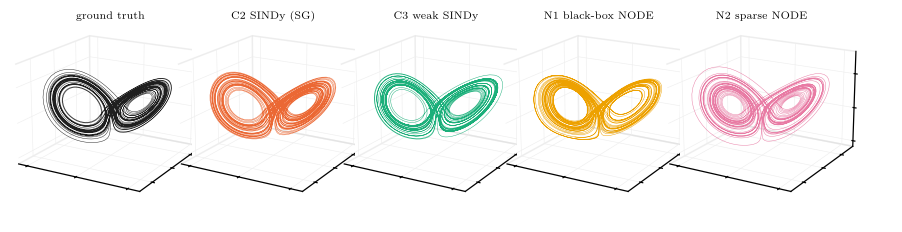

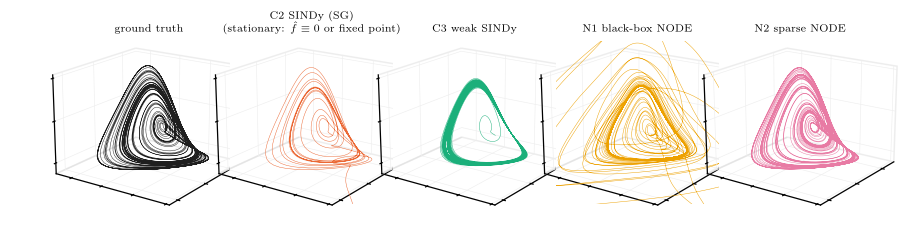

In [7]:
coefs = {**pickle.load(open(f"{MET}/classical_coefs.pkl", "rb")), **pickle.load(open(f"{MET}/neural_coefs.pkl", "rb"))}

def free_run(name, method, r, eps, seed=0, periods=60):
    s = E.get_sys(name); ref = E.reference(name); h = float(ref["h"])
    n = int(round(periods * s.t_char / h)); x0 = ref["X_ref"][:1]
    if method == "N1-MLP":
        _, model, _ = E.run_neural(name, r, eps, seed, "N1-MLP", evaluate=False)
        return rollout_model(model, x0, n, h)[:, 0]
    lib = PolyLibrary(s.d, 2, s.symbols)
    Xi = coefs[(name, method, round(r, 5), eps, seed, False)]
    return rollout_np(poly_field(lib, Xi), x0, n, h)[:, 0]

gallery = [("C2-SINDy-SG", "C2 SINDy (SG)"), ("C3-WSINDy", "C3 weak SINDy"),
           ("N1-MLP", "N1 black-box NODE"), ("N2-Lib", "N2 sparse NODE")]
for name, r, eps in [("lorenz", 4/15, 0.01), ("lorenz", 1/15, 0.05), ("lv4", 1/15, 0.01)]:
    ref = E.reference(name); s = E.get_sys(name)
    fig = plt.figure(figsize=(7.4, 1.75))
    runs = [("truth", ref["X_ref"][: int(60 * s.t_char / ref["h"])])] + [(m, free_run(name, m, r, eps)) for m, _ in gallery]
    for k, (m, X) in enumerate(runs):
        ax = fig.add_subplot(1, 5, k + 1, projection="3d")
        ok = np.isfinite(X).all(axis=1)
        Xp = X[ok]
        if len(Xp) > 1:
            ax.plot(Xp[:, 0], Xp[:, 1], Xp[:, 2], lw=0.3, color=P.COLORS[m] if m != "truth" else "#1f1f1f")
        lo, hi = ref["X_ref"].min(0), ref["X_ref"].max(0); pad = 0.15 * (hi - lo)
        ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0]); ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1]); ax.set_zlim(lo[2] - pad[2], hi[2] + pad[2])
        title = "ground truth" if m == "truth" else dict(gallery)[m]
        if m != "truth":
            tail = Xp[len(Xp) // 2:] if len(Xp) > 10 else Xp
            if not ok.all():
                title += "\n(diverges)"
            elif np.all(tail.std(axis=0) < 1e-6 * ref["std"]):
                title += "\n(stationary: $\\hat f\\equiv 0$ or fixed point)"
                ax.scatter([Xp[-1, 0]], [Xp[-1, 1]], [Xp[-1, 2]], s=12, color=P.COLORS[m])
            elif np.all(tail.std(axis=0) < 0.05 * ref["std"]):
                title += "\n(decays to a fixed point)"
            elif np.any(np.abs(Xp[-1] - ref["X_ref"].mean(0)) > 3 * (hi - lo)):
                title += "\n(leaves the attractor)"
        ax.set_title(title, fontsize=7); ax.set_xticklabels([]); ax.set_yticklabels([]); ax.set_zticklabels([])
        P.clean_3d(ax); ax.view_init(18, -60 if name == "lorenz" else 35)
        ax.set_box_aspect(None, zoom=1.3)
    fig.subplots_adjust(wspace=0.0, left=0, right=1, top=0.86, bottom=0.0)
    P.save(fig, f"fig06_gallery_{name}_dt{r:.3f}_n{eps:.2f}")
    plt.show()

## Key numbers quoted in the paper

In [8]:
def med(name, m, r, e, col):
    sub = common[(common.system == name) & (common.method == m) & (common.dt_ratio == round(r, 5)) & (common.noise == e)]
    return float(sub[col].median()) if len(sub) else float("nan")

key = {}
for name in ["lorenz", "lv4"]:
    for m in METHODS:
        for (r, e) in CONFIGS:
            for col in ["coef_err", "f1", "vpt_id", "vpt_ood", "w1", "lyap_relerr", "diverged_long", "exact_support"]:
                key[f"{name}|{m}|{r:.4f}|{e:.2f}|{col}"] = med(name, m, r, e, col)
json.dump(key, open(f"{MET}/key_numbers.json", "w"), indent=0)
# exact-support rate over all seeds and common configs
common.groupby(["system", "method"])["exact_support"].mean().unstack("method").round(2)

method,C1-OLS,C2-SINDy-FD,C2-SINDy-SG,C3-WSINDy,N1-MLP,N2-Lib,N2-Lib-WS
system,,,,,,,
lorenz,0.0,0.11,0.22,0.41,0.0,0.33,0.33
lv4,0.0,0.00,0.00,0.15,0.0,0.11,0.11


In [9]:
# best method per configuration (lowest median coefficient error)
best = (common.groupby(["system", "dt_ratio", "noise", "method"]).coef_err.median().reset_index()
        .sort_values("coef_err").groupby(["system", "dt_ratio", "noise"]).head(1))
best.sort_values(["system", "noise", "dt_ratio"])

,system,dt_ratio,noise,method,coef_err
12,lorenz,0.06667,0.00,N2-Lib,0.000010
3,lorenz,0.01333,0.01,C3-WSINDy,0.000360
17,lorenz,0.06667,0.01,C3-WSINDy,0.006058
54,lorenz,0.13333,0.01,N2-Lib,0.030544
61,lorenz,0.26667,0.01,N2-Lib,0.051890
24,lorenz,0.06667,0.02,C3-WSINDy,0.013161
34,lorenz,0.06667,0.05,N2-Lib-WS,0.088524
40,lorenz,0.06667,0.10,N2-Lib,0.213243
45,lorenz,0.06667,0.20,C3-WSINDy,0.361717
73,lv4,0.06667,0.00,C3-WSINDy,0.000190
